# 03 - Rating Factor EDA

In [37]:
# Import LIbraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2

# Display all columns
pd.set_option('display.max_columns', None)

In [38]:
# Read merged data from Parquet file
fmv_df = pd.read_parquet("fmv_df.parquet")

fmv_df.head()

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,ClaimAmount
0,1.0,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82,NaN
1,3.0,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82,NaN
2,5.0,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22,NaN
3,10.0,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72,NaN
4,11.0,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72,NaN


In [39]:
# Check for missing values and non-positive values
print("Missing values:")
print(fmv_df[["ClaimNb", "DrivAge", "VehAge", "BonusMalus", "Density", "VehPower", "Area", "Exposure"]].isna().sum())

print("\nNon-positive Exposure count:")
print((fmv_df["Exposure"] <= 0).sum())

print("\nNon-positive Density count:")
print((fmv_df["Density"] <= 0).sum())

print("\nInfinite values:")
print(np.isinf(fmv_df[["ClaimNb", "DrivAge", "VehAge", "BonusMalus", "Density", "Exposure"]]).sum())

Missing values:
ClaimNb       0
DrivAge       0
VehAge        0
BonusMalus    0
Density       0
VehPower      0
Area          0
Exposure      0
dtype: int64

Non-positive Exposure count:
0

Non-positive Density count:
0

Infinite values:
ClaimNb       0
DrivAge       0
VehAge        0
BonusMalus    0
Density       0
Exposure      0
dtype: int64


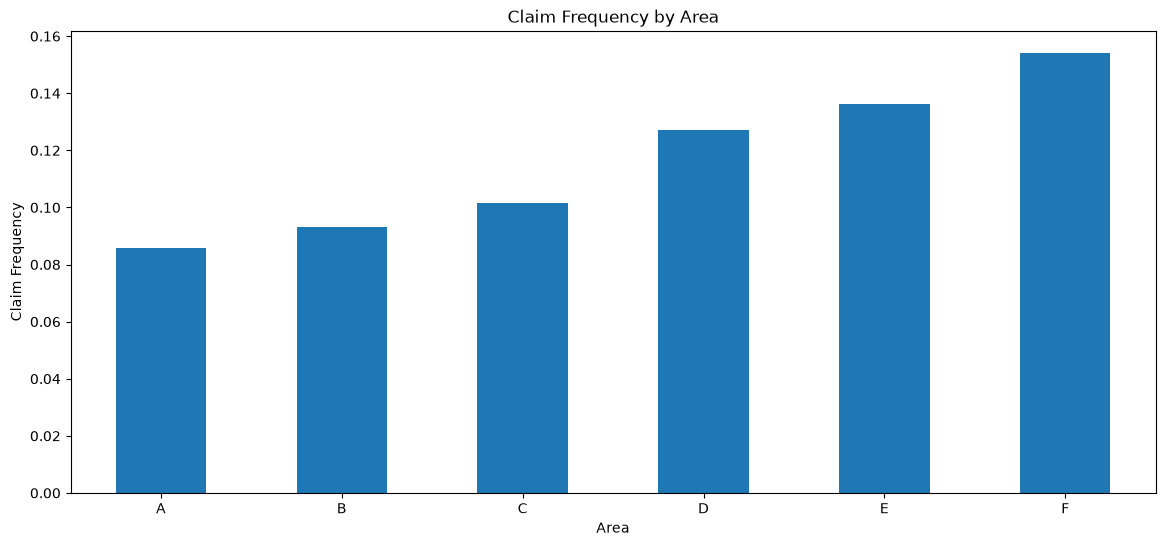

In [40]:
# What are the claim frequencies by Area
frequency_by_area = fmv_df.groupby('Area').apply(
    lambda x: x['ClaimNb'].sum() / x['Exposure'].sum()
)

plt.figure(figsize=(14,6))

frequency_by_area.plot(kind='bar')

plt.title("Claim Frequency by Area")
plt.xlabel("Area")
plt.ylabel("Claim Frequency")
plt.xticks(rotation=0)

plt.show()

############################## Takeaway ############################## 
# Claim frequency rises as Area becomes more urban - which sounds reasonable.

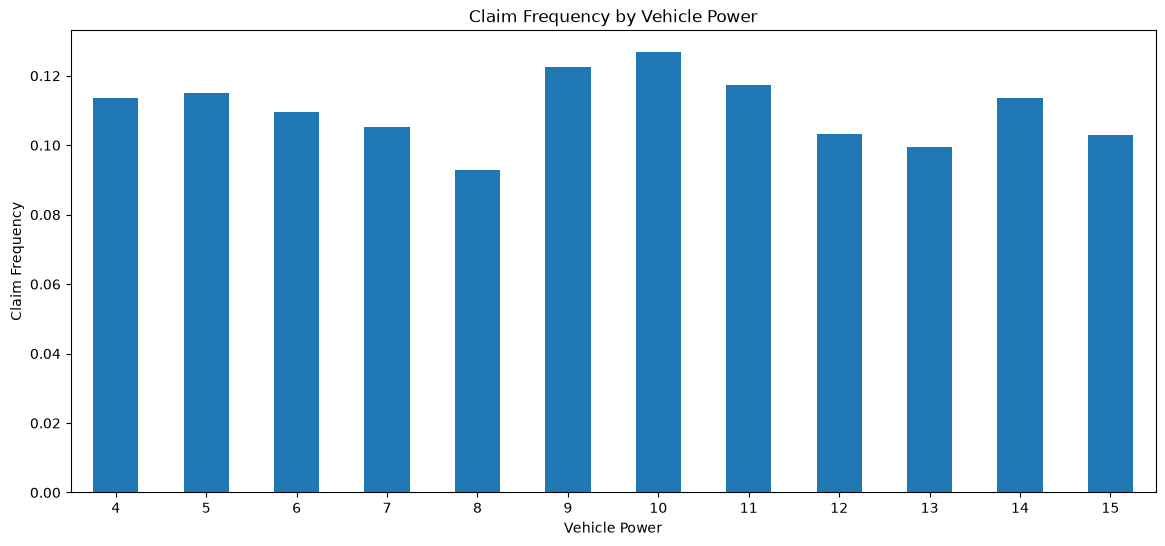

In [41]:
# What are the claim frequencies by Vehicle Power
frequency_by_power = fmv_df.groupby('VehPower').apply(
    lambda x: x['ClaimNb'].sum() / x['Exposure'].sum()
)

plt.figure(figsize=(14,6))

frequency_by_power.plot(kind='bar')

plt.title("Claim Frequency by Vehicle Power")
plt.xlabel("Vehicle Power")
plt.ylabel("Claim Frequency")
plt.xticks(rotation=0)

plt.show()

############################## Takeaway ############################## 
# Claim frequency does not monotonically increase with Vehicle Power. Relationship between Vehicle Power and claims may be non-linear.

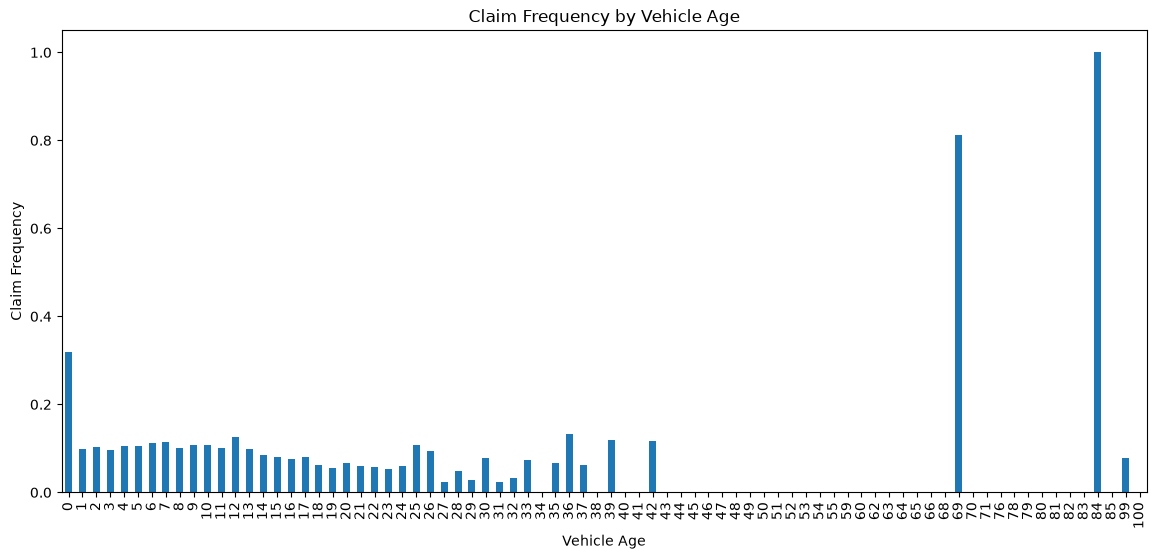

In [42]:
# What are the claim frequencies by Vehicle Age
frequency_by_age = fmv_df.groupby('VehAge').apply(
    lambda x: x['ClaimNb'].sum() / x['Exposure'].sum()
)

plt.figure(figsize=(14,6))

frequency_by_age.plot(kind='bar')

plt.title("Claim Frequency by Vehicle Age")
plt.xlabel("Vehicle Age")
plt.ylabel("Claim Frequency")
plt.xticks(rotation=90)

plt.show()

############################## Takeaway ##############################
# Claim frequency is high for brand new cars, before falling and leveling off relatively
# There are some outlier older cars with high claim frequencies. The number of actual claims are low


In [43]:
# Distribution of Vehicle Age
fmv_df['VehAge'].value_counts().sort_index()

############################## Takeaway ##############################
# New cars are not necessarily the most common. 1-year old cars are most common

VehAge
0      57813
1      71440
2      59280
3      50367
4      43600
       ...  
83         2
84         1
85         1
99        23
100       25
Name: count, Length: 78, dtype: int64

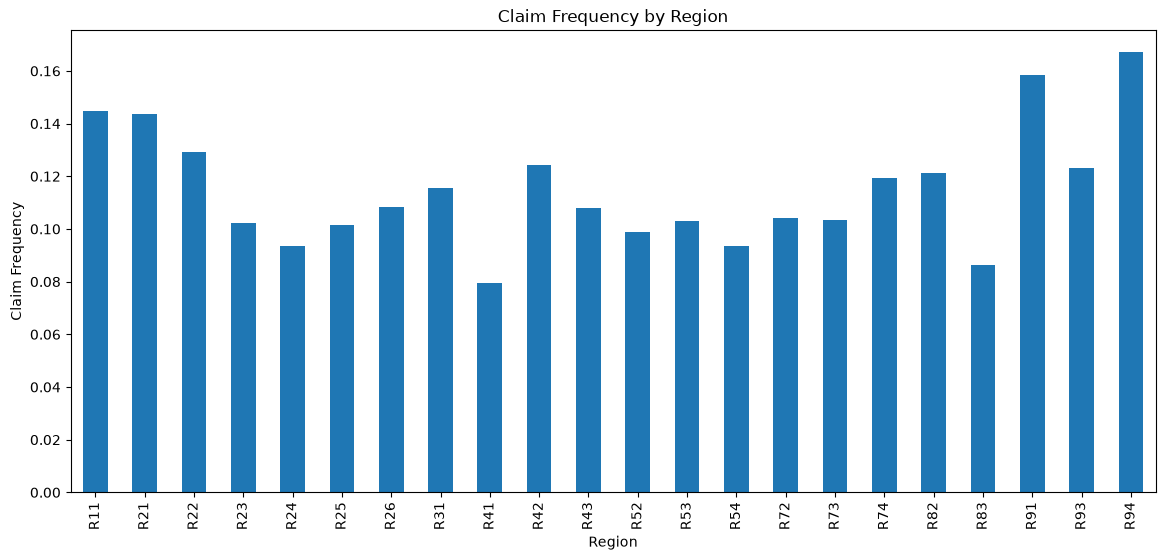

In [44]:
# What are the claim frequencies by Region
frequency_by_region = fmv_df.groupby('Region').apply(
    lambda x: x['ClaimNb'].sum() / x['Exposure'].sum()
)

plt.figure(figsize=(14,6))

frequency_by_region.plot(kind='bar')

plt.title("Claim Frequency by Region")
plt.xlabel("Region")
plt.ylabel("Claim Frequency")
plt.xticks(rotation=90)

plt.show()

############################## Takeaway ##############################
# Certain areas have clearly higher (or lower) claim frequencies

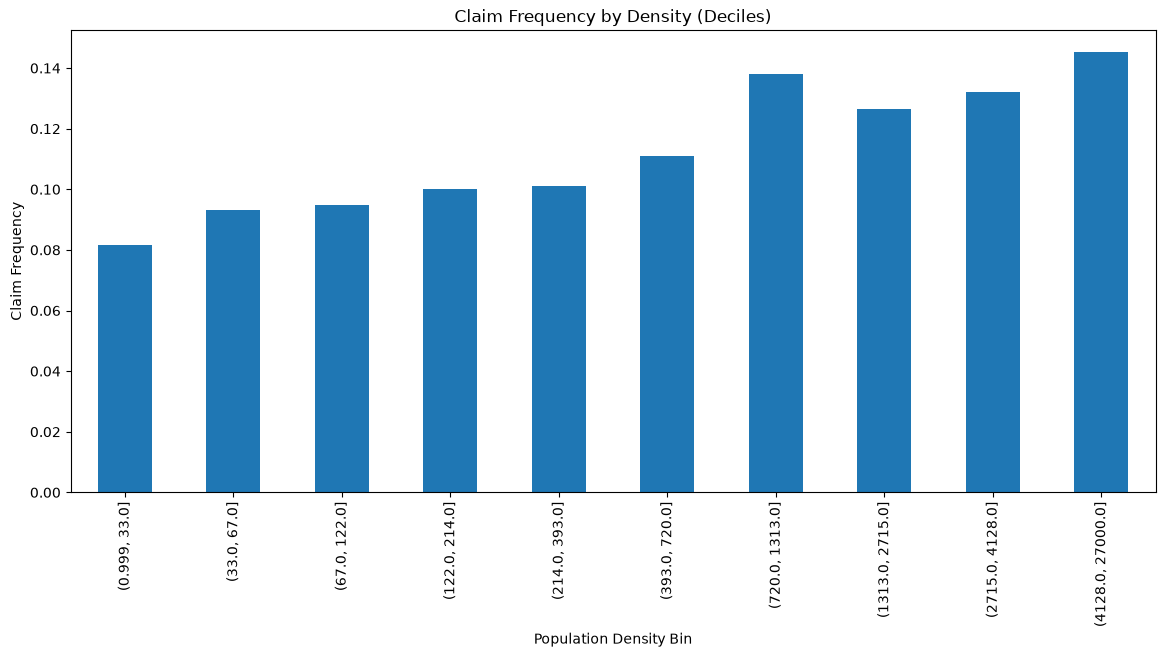

In [45]:
# What are the claim frequencies by Density

# Bin the densities first
fmv_df["DensityBin"] = pd.qcut(fmv_df["Density"], q=10)

frequency_by_density = fmv_df.groupby("DensityBin").apply(
    lambda x: x["ClaimNb"].sum() / x["Exposure"].sum()
)

plt.figure(figsize=(14,6))

frequency_by_density.plot(kind="bar")

plt.title("Claim Frequency by Density (Deciles)")
plt.xlabel("Population Density Bin")
plt.ylabel("Claim Frequency")

plt.xticks(rotation=90)

plt.show()

############################## Takeaway ##############################
# As the density increases, there is a general rising claim frequency trend, 
# as there are more opportunities for accidents to occur due to increasing congestion 

# There is a spike in Bin 7 (before reaching the highest density bins. Exposures are generally 
# decreasing as we go through the bins. However, Bin 7 had an increase in Exposures. 

<Axes: xlabel='DensityBin'>

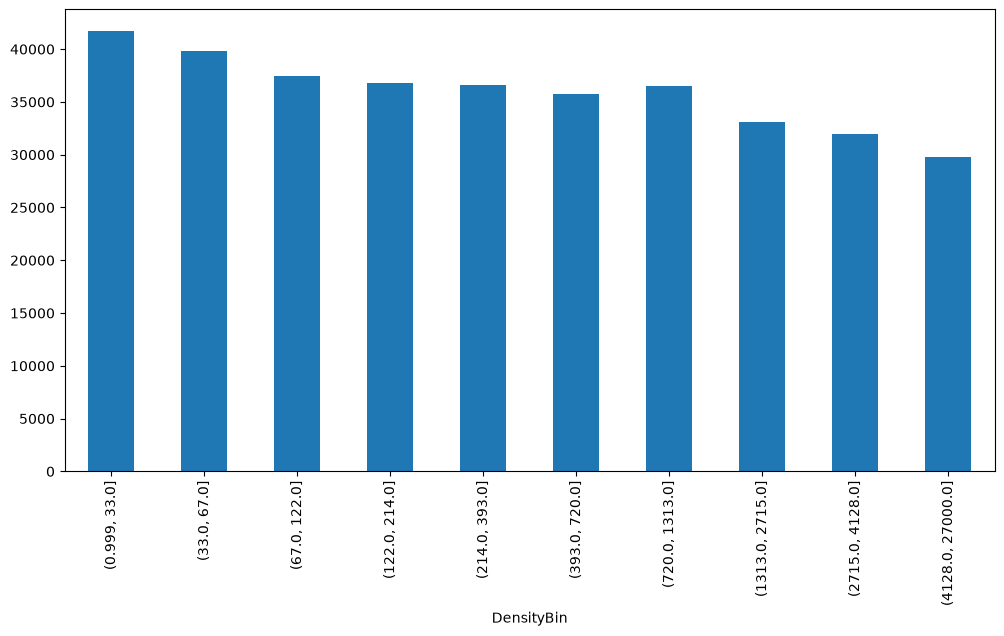

In [46]:
# What are the actual exposures per bin?
fmv_df.groupby("DensityBin")["Exposure"].sum().plot(kind="bar", figsize=(12,6))

############################## Takeaway ##############################
# Exposures seem to be credible per bucket

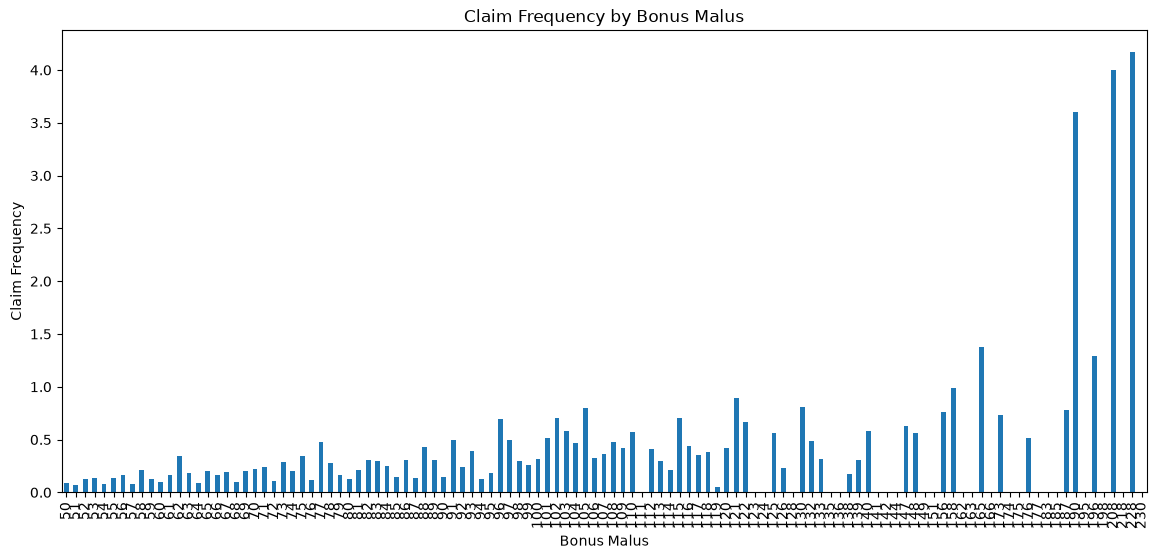

In [47]:
# What are the claim frequencies by Bonus Malus
frequency_by_bonusmalus = fmv_df.groupby('BonusMalus').apply(
    lambda x: x['ClaimNb'].sum() / x['Exposure'].sum()
)

plt.figure(figsize=(14,6))

frequency_by_bonusmalus.plot(kind='bar')

plt.title("Claim Frequency by Bonus Malus")
plt.xlabel("Bonus Malus")
plt.ylabel("Claim Frequency")
plt.xticks(rotation=90)

plt.show()

############################## Takeaway ##############################
# Claim frequency shows a growing trend by Bonus Malus, with a spike at the higher end
# A lower Bonus Malus is better for rating, so this claim frequency distribution is reasonable


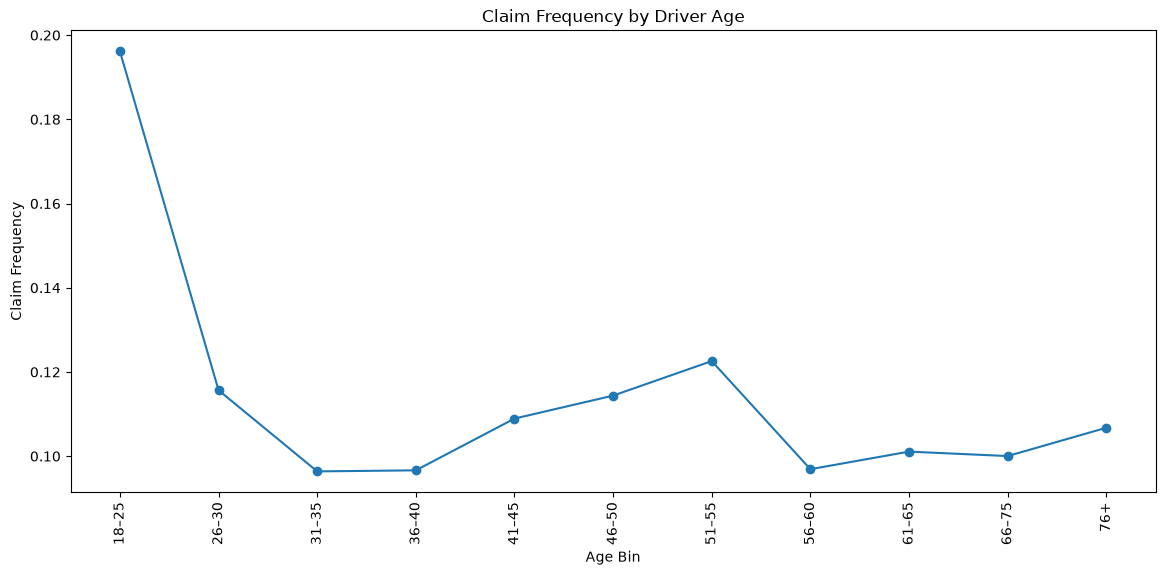

In [48]:
# What is the average claim number by driver age

# fmv_df.groupby('DrivAge')['ClaimNb'].mean()

age_bins = [18, 25, 30, 35, 40, 45, 50, 55, 60, 65, 75, 100]
age_labels = [
    "18–25","26–30","31–35","36–40","41–45",
    "46–50","51–55","56–60","61–65","66–75","76+"
]

fmv_df["AgeBin"] = pd.cut(fmv_df["DrivAge"], bins=age_bins, labels=age_labels)

age_stats = fmv_df.groupby("AgeBin").agg({
    "ClaimNb": "sum",
    "Exposure": "sum"
})

age_stats["Frequency"] = age_stats["ClaimNb"] / age_stats["Exposure"]

plt.figure(figsize=(14,6))

plt.plot(age_stats["Frequency"], marker="o")

plt.title("Claim Frequency by Driver Age")
plt.xlabel("Age Bin")
plt.ylabel("Claim Frequency")

plt.xticks(rotation=90)

plt.show()

############################## Takeaway ##############################
# Age group 18-25 has the highest frequency of all age age_bins
# Frequency is at its lowest between ages 31 and 50, before rising again through age 55
# Frequency once again drops after age 55, likely because of reduced driving at these ages


<Axes: xlabel='AgeBin'>

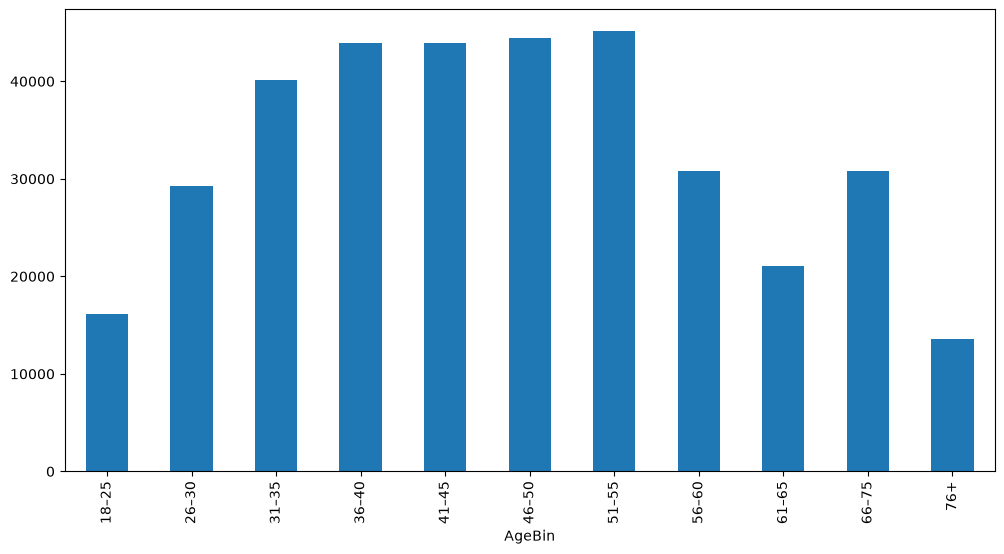

In [49]:
# What are the actual exposures per Age bin?
fmv_df.groupby("AgeBin")["Exposure"].sum().plot(kind="bar", figsize=(12,6))

############################## Takeaway ##############################
# Exposures seem to be credible per bucket

array([[<Axes: title={'center': 'DrivAge'}>,
        <Axes: title={'center': 'VehAge'}>],
       [<Axes: title={'center': 'BonusMalus'}>,
        <Axes: title={'center': 'Density'}>]], dtype=object)

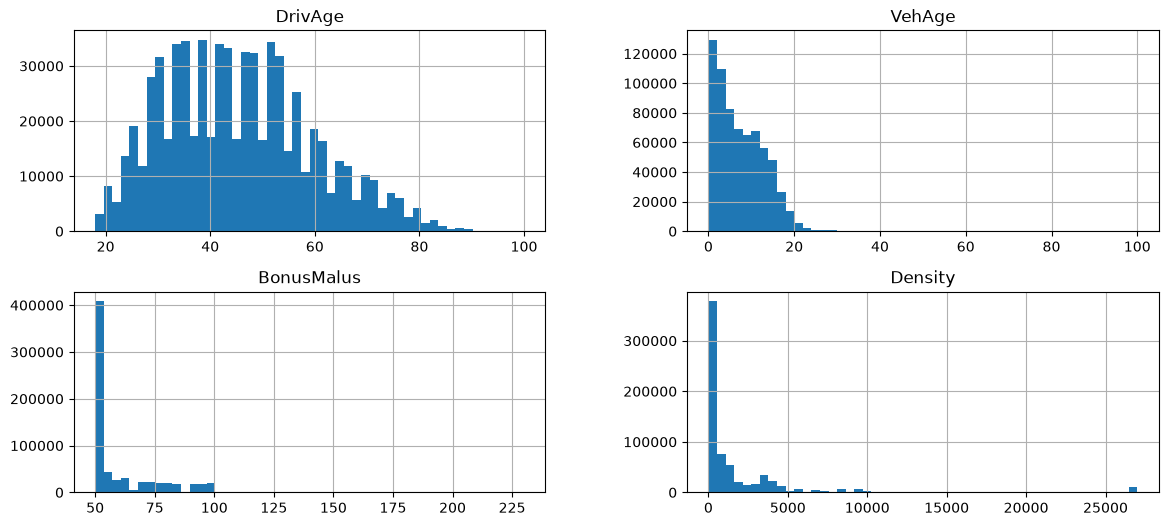

In [50]:
# What are the distributions for the numeric variables?

fmv_df[['DrivAge','VehAge','BonusMalus','Density']].hist(bins=50, figsize=(14,6))

############################## Takeaway ##############################
# The distribution of driver ages seem reasonable - with fewer younger and older drivers 
# and a concentration of drivers in the middle age ranges. Driver Age could exhibit a 
# non-linear relationship with risk

# The distribution of vehicle ages seem reasonable - more newer vehicles than older vehicles
# The relationship between vehicle ages and risk may not necessarily be linear

# The Bonus Malus distribution suggests a substantial concentration of drivers having lower values
# Lower Bonus Malus ratings are better, so this variable should have a notable impact on risk,
# since Bonus Malus reflects past claim behavior. A transformation may be necessary due to skewness

# The Density distribution shows that the vast majority of records come from lower density areas
# The Density distribution is right-skewed, so a transformation may be necessary  


In [51]:
# What do extreme values look like for numerical variables
fmv_df[['DrivAge','VehAge','BonusMalus','Density']].describe(percentiles=[.01,.05,.95,.99])

############################## Takeaway ##############################
###### Vehicle Age probably should be capped - possibly at 30 years old (clip(upper=30))

# Min and median Bonus Malus are the same

###### Density is highly skewed. Could benefit from a transformation


,DrivAge,VehAge,BonusMalus,Density
count,679513.000000,679513.000000,679513.000000,679513.000000
mean,45.497617,7.043808,59.784621,1794.052255
std,14.140106,5.664855,15.666953,3960.829098
min,18.000000,0.000000,50.000000,1.000000
1%,20.000000,0.000000,50.000000,10.000000
5%,25.000000,0.000000,50.000000,20.000000
95%,72.000000,17.000000,95.000000,7313.000000
99%,80.000000,21.000000,106.000000,27000.000000
max,100.000000,100.000000,230.000000,27000.000000


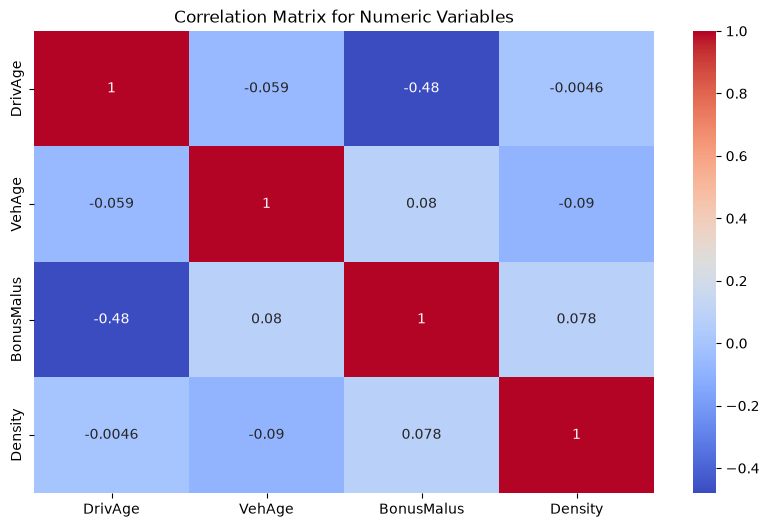

In [52]:
# What are the numeric variable correlatios?

corr = fmv_df[['DrivAge','VehAge','BonusMalus','Density']].corr()

plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap="coolwarm")

plt.title("Correlation Matrix for Numeric Variables")
plt.show()

############################## Takeaway ##############################
# Bonus Malus and Driver Age show a moderate negative correlation
# Generally, older drivers tend to have better claim histories
# and younger drivers tend to have worse claim histories

##### Since the correlation is not stronger, both variables can be included 

In [53]:
# How do claim frequency vary across categorical rating variables?
vehpower_stats = fmv_df.groupby("VehPower").agg({
    "Exposure":"sum",
    "ClaimNb":"sum"
})

vehpower_stats["Frequency"] = vehpower_stats["ClaimNb"] / vehpower_stats["Exposure"]

overall_freq = fmv_df["ClaimNb"].sum() / fmv_df["Exposure"].sum()

vehpower_stats["Relativity"] = vehpower_stats["Frequency"] / overall_freq

print(vehpower_stats)

############################## Takeaway ##############################
# Vehicle power showed the highest risks at the mid power levels (8 and 9)
# The relationship between vehicle power and claim frequency is not strictly monotonic

# At the highest vehicle power ranges, there is a substantial reduction in exposures 
# Low exposure categories may require combining categories

              Exposure  ClaimNb  Frequency  Relativity
VehPower                                              
4         60229.297304     6839   0.113549    1.026006
5         68376.398821     7872   0.115127    1.040265
6         82758.293871     9069   0.109584    0.990178
7         78156.506700     8237   0.105391    0.952290
8         22745.286305     2110   0.092766    0.838217
9         15392.943656     1884   0.122394    1.105922
10        15429.960824     1955   0.126702    1.144846
11         8532.898452     1001   0.117311    1.059992
12         3803.448343      393   0.103327    0.933642
13         1640.305322      163   0.099372    0.897900
14         1187.890391      135   0.113647    1.026887
15         1261.999173      130   0.103011    0.930785


          ClaimAmount
VehPower             
4         2350.757789
5         1727.809803
6         2281.672772
7         2221.776714
8         1796.149246
9         5135.289057
10        2344.545875
11        1837.720112
12        2390.818514
13        2233.838705
14        3182.376139
15        1294.515000


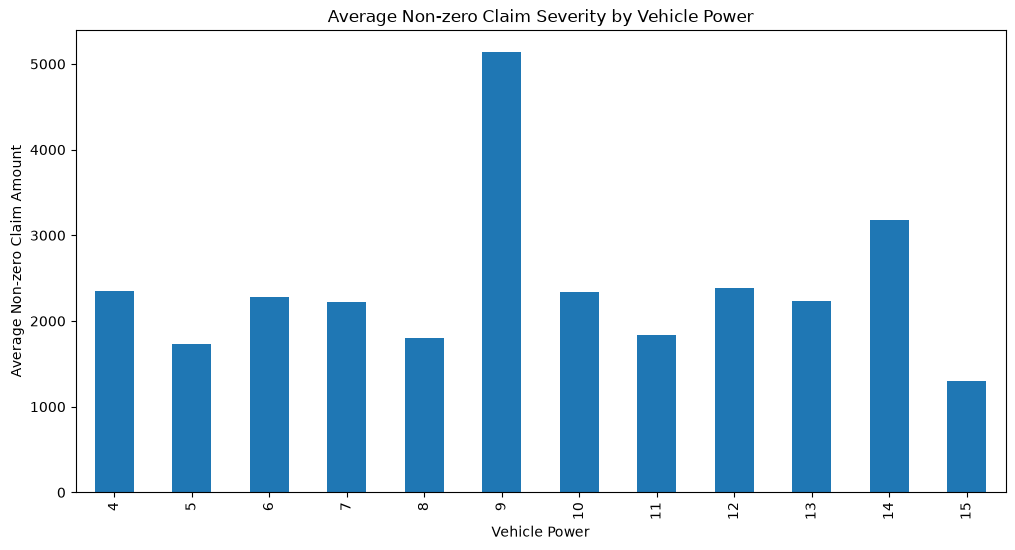

In [54]:
# How do things look with the focus on non-zero claims?

non_zero_sev_df = fmv_df[fmv_df["ClaimNb"] > 0].copy()
non_zero_sev_df["Severity"] = non_zero_sev_df["ClaimAmount"] / non_zero_sev_df["ClaimNb"]

severity_stats = non_zero_sev_df.groupby("VehPower").agg({
    "ClaimAmount":"mean"
})

print(severity_stats)

plt.figure(figsize=(12,6))

non_zero_sev_df.groupby("VehPower")["ClaimAmount"].mean().plot(kind="bar")

plt.title("Average Non-zero Claim Severity by Vehicle Power")
plt.xlabel("Vehicle Power")
plt.ylabel("Average Non-zero Claim Amount")

plt.show()

############################## Takeaway ##############################
# For claims with non-zero incurred values, vehicles with power value 9.0 stand out as 
# having the highest severity.
# Average Non-zero Claim Severity does not show a monotonic pattern by vehicle power.